In [80]:
import pandas as pd
import yaml 
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from decimal import Decimal
from datetime import datetime
from dateutil import parser
import networkx as nx

data exploration

In [81]:
df_users = pd.read_csv('users.csv')
df_users = pd.DataFrame(df_users)

df_books = yaml.safe_load(open('books.yaml'))
df_books = pd.DataFrame(df_books)

df_orders = pq.read_table('orders.parquet').to_pandas()
df_orders = pq.ParquetDataset('orders.parquet').read().to_pandas()

In [82]:
df_users.head()
len(df_users)
df_users.info()

df_users.duplicated().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3394 entries, 0 to 3393
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       3394 non-null   int64
 1   name     3394 non-null   str  
 2   address  3261 non-null   str  
 3   phone    3394 non-null   str  
 4   email    3394 non-null   str  
dtypes: int64(1), str(4)
memory usage: 466.0 KB


np.int64(0)

In [83]:
print(type(df_books))
df_books.info()
print(df_books.isna().sum(), "\n")
print(df_books.duplicated().sum())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   :id         749 non-null    int64 
 1   :title      749 non-null    str   
 2   :author     749 non-null    str   
 3   :genre      749 non-null    str   
 4   :publisher  747 non-null    str   
 5   :year       747 non-null    object
dtypes: int64(1), object(1), str(4)
memory usage: 84.2+ KB
:id           0
:title        0
:author       0
:genre        0
:publisher    2
:year         2
dtype: int64 

0


In [84]:
len(df_orders)
df_orders.info()
print(df_orders.isna().sum(), "\n")
print(df_orders.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10493 entries, 0 to 10492
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          10493 non-null  int64
 1   user_id     10493 non-null  int64
 2   book_id     10493 non-null  int64
 3   quantity    10493 non-null  int32
 4   unit_price  10493 non-null  str  
 5   timestamp   10493 non-null  str  
 6   shipping    7913 non-null   str  
dtypes: int32(1), int64(3), str(3)
memory usage: 947.5 KB
id               0
user_id          0
book_id          0
quantity         0
unit_price       0
timestamp        0
shipping      2580
dtype: int64 

0


In [85]:
print(df_users.isna().sum(), "\n")
print(df_users.duplicated().sum())



id           0
name         0
address    133
phone        0
email        0
dtype: int64 

0


data cleaning

In [86]:
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].unique(), "\n")
print(df_orders['timestamp'].head(20))

0         $ 35
1      30.0USD
2     37.0 USD
3     52.99USD
4     USD25.25
5        29.0$
6     EUR37.50
7       29.00$
8       70.25$
9    EUR 26.50
Name: unit_price, dtype: str 

<ArrowStringArray>
[     '$ 35',   '30.0USD',  '37.0 USD',  '52.99USD',  'USD25.25',     '29.0$',
  'EUR37.50',    '29.00$',    '70.25$', 'EUR 26.50',
 ...
 '32.50 USD',  'EUR44.25', 'EUR 60.00',    '30.25$',  'USD41.25', '35.25 EUR',
    '€72.75',      '€ 37',   '32.50 €',    '67 USD']
Length: 6044, dtype: str 

0            09:28,10-Dec-2025
1     2025-06-25;05:00:01 A.M.
2     10:31:43 P.M. 2026-01-14
3         03:02:34;17-JUL-2026
4             2025-08-17 12:25
5     Fri Apr 10 15:32:26 2026
6      20-Jul-2025;01:00:12 AM
7      15-September-2025,16:55
8       2025-11-28 05:13:06 am
9            2026-01-08, 14:26
10       12/02/25, 09:05:54 pm
11         2025-12-23T04:36:49
12     2025-08-26T20:57:40.674
13        07:17:58 pm,01/12/25
14         2026-02-04T14:31:26
15     2025-05-02T17:57:35.917
16      

In [87]:
print(df_books[':year'].unique()[:20], "\n")

[1989 2007 1953 2001 1981 2002 2023 2011 1976 2015 2021 1898 1838 2024
 2009 2026 1992 2013 1997 1987] 



In [88]:
#function to change currency to usd and clean signs such as $ or eur

def convert_to_usd(unit_price):
    clean_price = unit_price.replace("$", "").replace("EUR", "").replace("€", "").replace("USD", "").replace("¢", ".").strip()
   
    if "€" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("€", ".").replace("¢", "")
        return Decimal(clean_price) * Decimal("1.2")

    if "$" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("$", ".").replace("¢", "")
        return Decimal(clean_price)
    value = Decimal(clean_price)
    if "EUR" in unit_price or "€" in unit_price:
        currency = value * Decimal("1.2")
    elif "$" in unit_price or "USD" in unit_price:
        currency = value
    else:
        raise ValueError("Unsupported currency")
    
    return currency

In [89]:
print(convert_to_usd("EUR72.75"))  # test

87.300


In [90]:
df_orders['unit_price'] = df_orders['unit_price'].apply(convert_to_usd)
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].isna().sum())

0        35
1      30.0
2      37.0
3     52.99
4     25.25
5      29.0
6    45.000
7     29.00
8     70.25
9    31.800
Name: unit_price, dtype: object 

0


In [91]:
#paid price = quentity * unit_price
df_orders['paid_price'] = df_orders['quantity'] * df_orders['unit_price']
print(df_orders[['quantity', 'unit_price', 'paid_price']].head(20))


    quantity unit_price paid_price
0          2         35         70
1          1       30.0       30.0
2          2       37.0       74.0
3          1      52.99      52.99
4          1      25.25      25.25
5          1       29.0       29.0
6          1     45.000     45.000
7          1      29.00      29.00
8          1      70.25      70.25
9          3     31.800     95.400
10         4       63.5      254.0
11         2      28.00      56.00
12         3         55        165
13         1       18.0       18.0
14         1      37.75      37.75
15         1         36         36
16         1       40.0       40.0
17         1     81.600     81.600
18         1         73         73
19         1      25.75      25.75


In [92]:
def timestamp_parser(value):
    try:
        value = str(value).strip()
        value = value.replace(",", " ").replace(";"," ")
        value = value.replace("A.M.", "AM").replace("P.M.", "PM")
        return parser.parse(value)
    except(ValueError, TypeError):
        return pd.NaT
    

In [93]:
df_orders['parsed_timestamp'] = df_orders['timestamp'].apply(timestamp_parser)
print(df_orders['parsed_timestamp'].isna().sum())

0


In [94]:
print(df_orders.columns.tolist())

['id', 'user_id', 'book_id', 'quantity', 'unit_price', 'timestamp', 'shipping', 'paid_price', 'parsed_timestamp']


In [95]:
df_orders['date'] = pd.to_datetime(df_orders['parsed_timestamp']).dt.date
print(df_orders[['parsed_timestamp', 'date']].head(5))

     parsed_timestamp        date
0 2025-12-10 09:28:00  2025-12-10
1 2025-06-25 05:00:01  2025-06-25
2 2026-01-14 22:31:43  2026-01-14
3 2026-07-17 03:02:34  2026-07-17
4 2025-08-17 12:25:00  2025-08-17


In [96]:
daily_revenue = df_orders.groupby('date')['paid_price'].sum()
top5rev = daily_revenue.sort_values(ascending = False).head(5)
print(top5rev)

date
2025-09-22    3395.39878
2025-09-10    3339.30400
2025-08-20    3298.50688
2025-10-17      3252.320
2026-01-15    3134.12400
Name: paid_price, dtype: object


In [97]:
def same_user(user1, user2):
    columns = ['name', 'address', 'phone', 'email']
    matches = 0

    for col in columns:
        if pd.notna(user1[col]) and pd.notna(user2[col]):
            if user1[col] == user2[col]:
                matches += 1

    return matches >= 3

In [98]:
G = nx.Graph()
for user_id in df_users['id']:
    G.add_node(user_id)
for i in range(len(df_users)):
    for j in range(i + 1, len(df_users)):
        user1 = df_users.iloc[i]
        user2 = df_users.iloc[j]

        if same_user(user1, user2):
            G.add_edge(user1['id'], user2['id'])

In [99]:
groups = list(nx.connected_components(G))
unique_users_count = len(groups)
print("Total user ID:", len(df_users))
print("Unique users:", unique_users_count)

Total user ID: 3394
Unique users: 3221


In [100]:
user_mapping = {}
for group in groups:
    real_id = min(group)
    for user_id in group:
        user_mapping[user_id] = real_id

df_users['real_user_id'] = df_users['id'].map(user_mapping)
print(df_users[['id', 'real_user_id']].head(10))

      id  real_user_id
0  50033         50033
1  49617         49617
2  47571         47571
3  47967         47967
4  49031         49031
5  49538         49538
6  48897         48897
7  47429         47429
8  47374         47374
9  48144         48144


In [101]:
multiple_ids = [group for group in groups if len(group) > 1]

print("Users with multiple IDs:", len(multiple_ids))
print("Examples:", multiple_ids[:15])

Users with multiple IDs: 164
Examples: [{np.int64(47258), 48931}, {49393, np.int64(46850)}, {49362, np.int64(47931)}, {np.int64(47556), 47165}, {47296, np.int64(46973)}, {47912, np.int64(49469)}, {np.int64(48232), 47046}, {np.int64(49021), 48575}, {49137, np.int64(47837)}, {49802, np.int64(48404)}, {np.int64(49912), 48886}, {np.int64(49666), 47267, np.int64(48461)}, {48217, np.int64(47564), np.int64(48007)}, {np.int64(47156), 47838}, {47066, np.int64(50099)}]


In [102]:
print("Total groups:", len(groups))
print("Multiple ID groups:", len(multiple_ids))

for group in multiple_ids[:5]:
    display(df_users[df_users['id'].isin(group)])

Total groups: 3221
Multiple ID groups: 164


,id,name,address,phone,email,real_user_id
15,48931,Ira Moen Esq.,"Suite 521 627 Scotty Haven, Chiquitamouth, WI ...",(785) 134-2247,floyd@botsford.test,47258
987,47258,Ira Moen Esq.,"Apt. 291 60917 Onita Road, Lakiaborough, WI 36...",(785) 134-2247,floyd@botsford.test,47258


,id,name,address,phone,email,real_user_id
18,49393,Eldora Legros,"5259 Lindsey Manors, West Marcela, SC 69730",411 551 3017,corrinne@lindgren-stark.example,46850
610,46850,Eldora Legros,"138 Rufus Ville, Hilllhaven, HI 39432-4368",411 551 3017,corrinne@lindgren-stark.example,46850


,id,name,address,phone,email,real_user_id
28,49362,Kelli Halvorson,"Suite 345 6035 Nitzsche Common, Framimouth, NC...",(277) 140-4807,bronwyn_williamson@hane.test,47931
951,47931,Alane Skiles,"Suite 345 6035 Nitzsche Common, Framimouth, NC...",(277) 140-4807,bronwyn_williamson@hane.test,47931


,id,name,address,phone,email,real_user_id
29,47165,Mr. Etha Krajcik,"5548 Stark Inlet, Lockmanland, NM 15420",455 325 0613,brett_heathcote@champlin.test,47165
1061,47556,Mr. Etha Krajcik,"5548 Stark Inlet, Lockmanland, NM 15420",455 325 0613,damion_corkery@larson.example,47165


,id,name,address,phone,email,real_user_id
40,47296,Dr. Vincent Doyle,"810 Violette Row, Johnstown, MS 08127-4669",313.058.4313,nicky@crist.test,46973
3250,46973,Dr. Vincent Doyle,"810 Violette Row, Johnstown, MS 08127-4669",223-083-9963,nicky@crist.test,46973


In [103]:
print("Largest group:", max(len(group) for group in groups))

Largest group: 3


In [104]:
missing_address = df_users[df_users['address'].isna()]

print("Missing addresses:", len(missing_address))
print("Unique real users:", missing_address['real_user_id'].nunique())

Missing addresses: 133
Unique real users: 133


In [105]:
print(df_books.columns.tolist())
print(df_books[':author'].head(10).to_string())

[':id', ':title', ':author', ':genre', ':publisher', ':year']
0                              Amb. September Walter
1                                  Golda Satterfield
2               Miss Lorina Kertzmann, Darron Ernser
3                                       Nathan Hintz
4                                   Natalie Schuster
5                                  Mr. Shirley Tromp
6                             Msgr. Kris Satterfield
7    Willie Klocko, Frida Casper, Ms. Romeo Tremblay
8                     Emerson Lakin, Fr. Latoyia Orn
9                 Ms. Shanice Feeney, Stephnie Feest


In [106]:
def split_names(authors):
    names = authors.split(",")
    names = [name.strip() for name in names]
    return frozenset(names)

In [107]:
df_books['authors'] = df_books[':author'].apply(split_names)
unique_authors = df_books['authors'].nunique()
print("Unique authors:", unique_authors)

Unique authors: 324


In [113]:
print(df_books[[':author', 'authors']].head(5))

                                :author  \
0                 Amb. September Walter   
1                     Golda Satterfield   
2  Miss Lorina Kertzmann, Darron Ernser   
3                          Nathan Hintz   
4                      Natalie Schuster   

                                             authors  
0                 frozenset({Amb. September Walter})  
1                     frozenset({Golda Satterfield})  
2  frozenset({Darron Ernser, Miss Lorina Kertzmann})  
3                          frozenset({Nathan Hintz})  
4                      frozenset({Natalie Schuster})  


In [114]:
df_merged = df_orders.merge(df_books, left_on='book_id', right_on=':id')
author_sales = df_merged.groupby('authors')['quantity'].sum()
author_sales = author_sales.sort_values(ascending=False)

print(author_sales.head(5))

authors
frozenset({Darron Ernser, Miss Lorina Kertzmann})    173
frozenset({Ethan Cronin})                            144
frozenset({Ali Doyle})                               138
frozenset({Aida Macejkovic PhD})                     127
frozenset({Ms. Shanice Feeney, Stephnie Feest})      126
Name: quantity, dtype: int32


In [110]:
df_orders['real_user_id'] = df_orders['user_id'].map(user_mapping)

print(df_orders[['user_id', 'real_user_id', 'paid_price']].head(10))
print("Missing users:", df_orders['real_user_id'].isna().sum())

buyer_spending = df_orders.groupby('real_user_id')['paid_price'].sum()
buyer_spending = buyer_spending.sort_values(ascending=False)

print(buyer_spending.head(5))
best_buyer = buyer_spending.index[0]

buyer_ids = df_users[df_users['real_user_id'] == best_buyer]['id'].tolist()

print("Best buyer IDs:", buyer_ids)
print("Total spending:", buyer_spending.iloc[0])

   user_id  real_user_id paid_price
0    49038         49038         70
1    48585         48585       30.0
2    50023         50023       74.0
3    49445         49445      52.99
4    49693         49693      25.25
5    48703         48703       29.0
6    49355         49355     45.000
7    48457         48457      29.00
8    48835         48835      70.25
9    47649         47649     95.400
Missing users: 0
real_user_id
48288     1230.178
48095     1228.850
49547    1213.8350
46917     1187.150
47247    1184.4800
Name: paid_price, dtype: object
Best buyer IDs: [48288, 48610, 49309]
Total spending: 1230.178


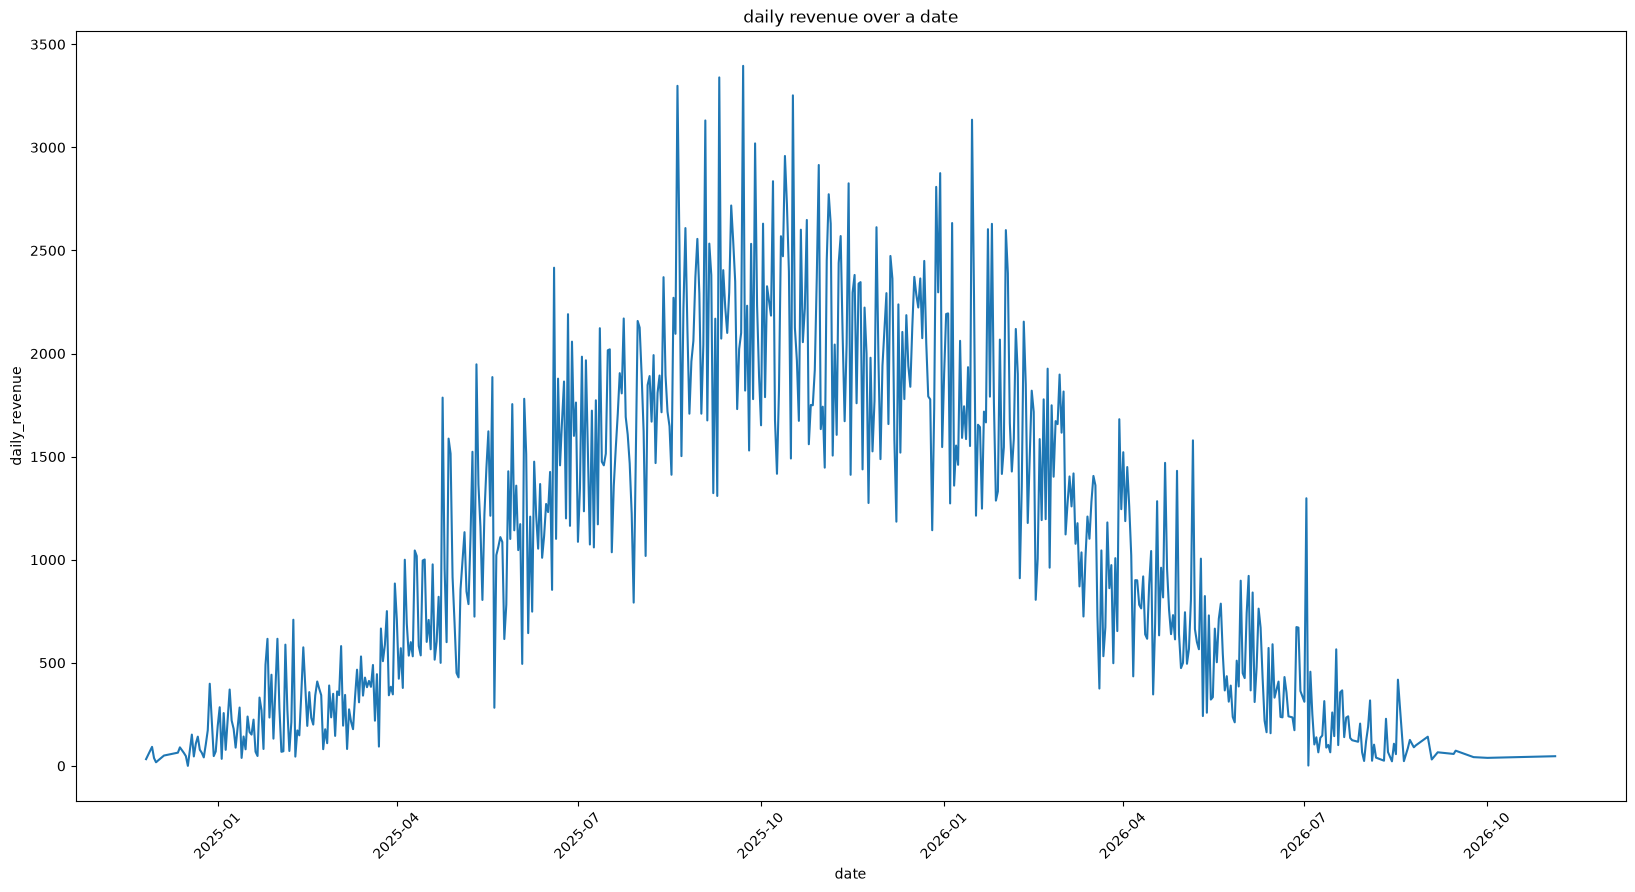

In [115]:
daily_revenue = daily_revenue.sort_index()
plt.figure(figsize=(20, 10))
plt.plot(daily_revenue.index, daily_revenue.astype(float))
plt.xlabel('date')
plt.xticks(rotation=45)
plt.ylabel('daily_revenue')
plt.title('daily revenue over a date')
plt.show()